In [12]:
import os
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

# Load the cleaned data
path = r"D:\data_projects\kenya-food-prices\data\processed\prices_clean.csv"
print("File exists:", os.path.exists(path))
print("Last updated:", time.ctime(os.path.getmtime(path)))

df = pd.read_csv(path, parse_dates=["date"])

# Quick checks
print("\nShape:", df.shape)
print("Date range:", df["date"].min().date(), "to", df["date"].max().date())
print("Has standardized price column:", "price_per_std" in df.columns)
print("Rows with unconverted unit:", df["unit_qty"].isna().sum())

df.info()
df.head()

File exists: True
Last updated: Thu Oct 15 14:57:20 2026

Shape: (27541, 22)
Date range: 2006-01-15 to 2026-09-15
Has standardized price column: True
Rows with unconverted unit: 639
<class 'pandas.DataFrame'>
RangeIndex: 27541 entries, 0 to 27540
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              27541 non-null  datetime64[us]
 1   admin1            27492 non-null  str           
 2   admin2            27492 non-null  str           
 3   market            27541 non-null  str           
 4   market_id         27541 non-null  int64         
 5   latitude          27492 non-null  float64       
 6   longitude         27492 non-null  float64       
 7   category          27541 non-null  str           
 8   commodity         27541 non-null  str           
 9   commodity_id      27541 non-null  int64         
 10  unit              27541 non-null  str           
 11  priceflag    

,date,admin1,admin2,market,market_id,latitude,longitude,category,commodity,commodity_id,unit,priceflag,pricetype,currency,price,usdprice,year,month,unit_qty,unit_type,price_per_std,usdprice_per_std
0,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize,51,KG,actual,Wholesale,KES,16.13,0.22,2006,1,1.00,kg,16.13,0.22
1,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,cereals and tubers,Maize (white),67,90 KG,actual,Wholesale,KES,"1,480.00",20.58,2006,1,90.00,kg,16.44,0.23
2,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans,50,KG,actual,Wholesale,KES,33.63,0.47,2006,1,1.00,kg,33.63,0.47
3,2006-01-15,Coast,Mombasa,Mombasa,191,-4.05,39.67,pulses and nuts,Beans (dry),262,90 KG,actual,Wholesale,KES,"3,246.00",45.15,2006,1,90.00,kg,36.07,0.50
4,2006-01-15,Eastern,Kitui,Kitui,187,-1.37,38.02,cereals and tubers,Maize (white),67,KG,actual,Retail,KES,17.00,0.24,2006,1,1.00,kg,17.00,0.24


In [13]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27541 entries, 0 to 27540
Data columns (total 22 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   date              27541 non-null  datetime64[us]
 1   admin1            27492 non-null  str           
 2   admin2            27492 non-null  str           
 3   market            27541 non-null  str           
 4   market_id         27541 non-null  int64         
 5   latitude          27492 non-null  float64       
 6   longitude         27492 non-null  float64       
 7   category          27541 non-null  str           
 8   commodity         27541 non-null  str           
 9   commodity_id      27541 non-null  int64         
 10  unit              27541 non-null  str           
 11  priceflag         27541 non-null  str           
 12  pricetype         27541 non-null  str           
 13  currency          27541 non-null  str           
 14  price             27541 non-null 

In [14]:
df.describe()

,date,market_id,latitude,longitude,commodity_id,price,usdprice,year,month,unit_qty,price_per_std,usdprice_per_std
count,27541,"27,541.00","27,492.00","27,492.00","27,541.00","27,541.00","27,541.00","27,541.00","27,541.00","26,902.00","26,902.00","26,902.00"
mean,2021-05-17 17:54:43.933045,"4,112.85",0.75,36.99,305.71,"1,330.36",12.16,"2,020.88",6.54,21.79,116.61,0.96
min,2006-01-15 00:00:00,184.00,-4.66,34.36,50.00,5.00,0.04,"2,006.00",1.00,0.20,0.28,0.00
25%,2021-02-15 00:00:00,"1,853.00",-1.27,34.85,67.00,70.00,0.60,"2,021.00",3.00,1.00,50.00,0.46
50%,2022-11-15 00:00:00,"3,254.00",0.35,36.78,181.00,130.00,1.03,"2,022.00",6.00,1.00,86.50,0.74
75%,2024-07-15 00:00:00,"5,670.00",3.51,39.02,451.00,"1,125.00",10.58,"2,024.00",9.00,50.00,136.07,1.09
max,2026-09-15 00:00:00,"10,509.00",4.62,41.86,937.00,"19,800.00",184.82,"2,026.00",12.00,126.00,900.00,6.96
std,NaN,"3,159.30",2.28,2.04,297.42,"2,600.64",23.12,4.78,3.49,36.16,114.67,0.90


In [15]:
#Missing values
print('Missing values:')
print(df.isna().sum()[df.isna().sum()>0])

Missing values:
admin1               49
admin2               49
latitude             49
longitude            49
unit_qty            639
unit_type           639
price_per_std       639
usdprice_per_std    639
dtype: int64


In [16]:
df.duplicated().sum()

np.int64(0)

In [17]:
# Retail vs wholesale
print("Price type:")
print(df["pricetype"].value_counts())

# Actual vs aggregate prices
print("\nPrice flag:")
print(df["priceflag"].value_counts())

# Most common commodities
print("\nTop 15 commodities by rows:")
print(df["commodity"].value_counts().head(15))

# Coverage over time
print("\nRows per year:")
print(df.groupby("year").size())

# Highest and lowest standardized prices
cols = ["date", "market", "commodity", "unit", "pricetype", "price_per_std"]
print("\nTop 10 highest price_per_std:")
print(df.nlargest(10, "price_per_std")[cols])

print("\nTop 10 lowest price_per_std:")
print(df.nsmallest(10, "price_per_std")[cols])

Price type:
pricetype
Retail       18266
Wholesale     9275
Name: count, dtype: int64

Price flag:
priceflag
actual              18355
aggregate            8943
actual,aggregate      243
Name: count, dtype: int64

Top 15 commodities by rows:
commodity
Beans (dry)                1864
Maize (white)              1651
Maize                      1538
Salt                       1397
Wheat flour                1367
Sugar                      1333
Potatoes (Irish)           1295
Beans                      1293
Rice (aromatic)            1024
Sorghum                    1021
Maize (white, dry)          974
Oil (vegetable)             837
Kale                        824
Milk (cow, pasteurized)     821
Maize flour (white)         755
Name: count, dtype: int64

Rows per year:
year
2006     349
2007     356
2008     385
2009     394
2010     393
2011     392
2012     372
2013     382
2014     403
2015     517
2016     522
2017     548
2018     570
2019     532
2020     302
2021    5644
2022    1892


#### What this means for the analysis
- Market coverage changed in 2021. Many more markets were added, so comparing a national average in 2015 with 2024 mixes price changes with changes in which markets are included. 
- Commodity names changed over time. Maize (white) stops in 2020, while Maize and Maize (white, dry) start later, so they need to be grouped. Sugar, wheat flour and salt only start in 2018.
- Camp markets are outliers for some goods, so consider excluding Kakuma and Dadaab when looking at national prices.

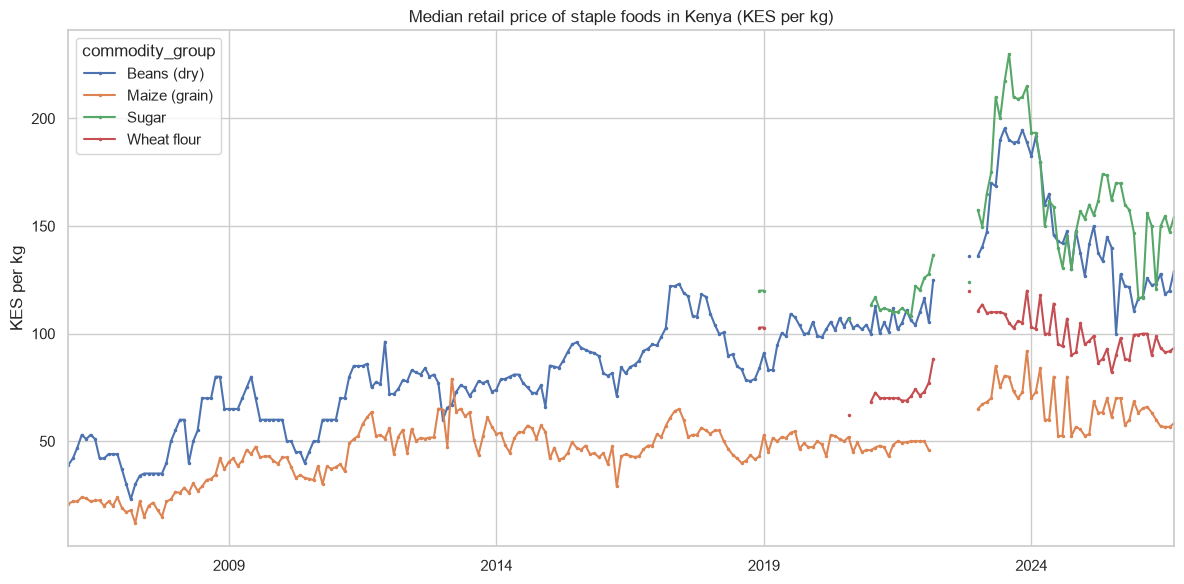

In [18]:
# STAPLE PRICE TRENDS
# Retail prices only, with a valid per-kg price
retail = df[(df["pricetype"] == "Retail")
            & (df["unit_type"] == "kg")
            & df["price_per_std"].notna()].copy()

# Group the maize name variants together
maize_names = ["Maize", "Maize (white)", "Maize (white, dry)"]
retail["commodity_group"] = retail["commodity"].where(
    ~retail["commodity"].isin(maize_names), "Maize (grain)"
)

staples = ["Maize (grain)", "Beans (dry)", "Sugar", "Wheat flour"]

# Monthly national median price per kg
monthly = (
    retail[retail["commodity_group"].isin(staples)]
    .groupby([pd.Grouper(key="date", freq="MS"), "commodity_group"])["price_per_std"]
    .median()
    .reset_index()
)

pivot = (monthly
         .pivot(index="date", columns="commodity_group", values="price_per_std")
         .asfreq("MS"))

ax = pivot.plot(figsize=(12, 6), marker=".", markersize=3)
ax.set_title("Median retail price of staple foods in Kenya (KES per kg)")
ax.set_xlabel("")
ax.set_ylabel("KES per kg")
plt.tight_layout()
plt.show()

Staple prices in Kenya peaked in 2023, with sugar up ~65% and dry beans up ~56% in median retail price versus 2022. Prices eased in 2024 to 2025 but stayed above 2022 levels. Sugar and wheat flour data before 2021 is too sparse (one observation per year) to show trends, and market coverage expanded sharply in 2021, so national medians before and after may not be directly comparable.

### SQL Analysis
The cleaned data was loaded into a SQLite database (`food_prices.db`) with `src/load.py`, and the queries below are stored in the `sql/` folder. All queries use retail prices converted to KES per kg, and maize name variants are grouped into one "Maize (grain)" category.

In [30]:
import sqlite3
con = sqlite3.connect("../food_prices.db")

def run_sql(name):
    with open(f"../sql/{name}.sql") as f:
        return pd.read_sql(f.read(), con)

In [31]:
run_sql('02_yoy_change')

,commodity_group,year,avg_price,prev_year_price,yoy_pct
0,Beans (dry),2006,46.00,NaN,NaN
1,Beans (dry),2007,34.92,46.00,-24.10
2,Beans (dry),2008,62.92,34.92,80.20
3,Beans (dry),2009,65.83,62.92,4.60
4,Beans (dry),2010,51.25,65.83,-22.10
5,Beans (dry),2011,78.86,51.25,53.90
6,Beans (dry),2012,78.54,78.86,-0.40
7,Beans (dry),2013,72.30,78.54,-7.90
8,Beans (dry),2014,76.06,72.30,5.20
9,Beans (dry),2015,90.97,76.06,19.60


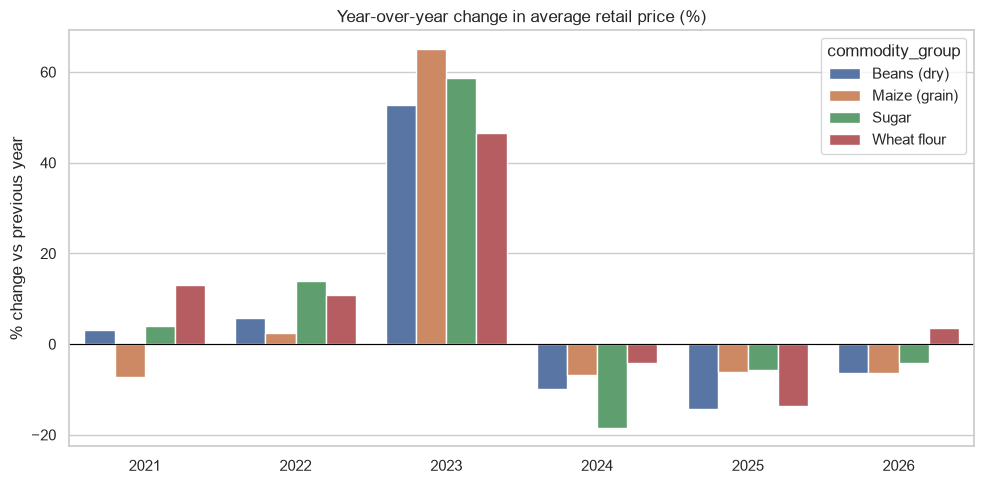

In [32]:
yoy = run_sql("02_yoy_change")

# Skip years with only one observation (sugar and wheat flour before 2021)
yoy = yoy[yoy["year"] >= 2021]

plt.figure(figsize=(10, 5))
sns.barplot(data=yoy, x="year", y="yoy_pct", hue="commodity_group")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Year-over-year change in average retail price (%)")
plt.xlabel("")
plt.ylabel("% change vs previous year")
plt.tight_layout()
plt.show()

### Year-over-year change chart

The 2023 spike appears in all four staples at the same time, with increases of roughly 47% to 65% over 2022. That points to a broad driver rather than a shock to one commodity. Prices fell in 2024 and 2025 but stayed above 2022 levels.

Years before 2021 are excluded from this chart because sugar and wheat flour have only one observation a year there. Whether the spike reflects local conditions, a weaker shilling or both still needs to be tested with the USD prices.

In [2]:
run_sql('03_county_ranking')

NameError: name 'run_sql' is not defined

Maize prices rose the most in Wajir (+59%, from 50 to 79 KES/kg), Baringo (+56%) and Turkana (+56%), with Marsabit and Isiolo close behind at about 50%. Garissa saw a smaller rise (+17%).

**Limitation:** only 6 counties have retail maize prices in both years, so this is not a national picture. It covers mostly arid and semi-arid counties, so the results should not be generalized to the whole country.

In [ ]:
run_sql('04_volatility')

,commodity,months,mean_price,std_dev,cv_pct
0,Beans (dry),241,91.90,35.30,38.40
1,Maize (white),180,44.90,12.80,28.50
2,Sorghum,56,69.40,15.80,22.80
3,Potatoes (Irish),63,72.70,15.00,20.60
4,Sugar,64,147.40,29.20,19.80
5,Meat (beef),50,561.00,108.90,19.40
6,Maize flour,61,86.30,16.80,19.40
7,Bread,178,101.40,18.50,18.20
8,Salt,63,59.90,10.30,17.10
9,Wheat flour,64,93.40,15.00,16.10


Dry beans were the most volatile (CV about 38%), followed by white maize (about 28%), sorghum (about 23%) and Irish potatoes (about 21%). Meat is much more expensive per kg but relatively stable (about 16 to 19%).

**Limitation:** this measure includes the long-run price rise, not only month-to-month swings, and commodities with longer histories (beans have 241 months) will tend to look more volatile. Treat it as a rough ranking, not a precise comparison.
